PROJECT NAME : COVID-19 CASES PREDICTIONS(JOHNS HOPKINS)

PROJECT TYPE : MACHINE LEARNING-PREDICTIVE ANALYSIS/REGRESSION

CONTRIBUTION : INDIVIDUAL

PROJECT SUMMARY:

The COVID-19 Cases Prediction project aims to analyze historical COVID-19 data and predict daily new confirmed cases using machine learning algorithms. The project uses datasets containing confirmed cases, deaths, and recovered cases to understand the spread and trends of the disease over time.

The system is developed using Python in Google Colab. Exploratory Data Analysis (EDA) and data preprocessing are performed to understand the dataset, handle missing values, and prepare the data for prediction. Three machine learning algorithms—Linear Regression, Random Forest Regressor, and XGBoost Regressor—are implemented and compared using evaluation metrics such as Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

The main objective is to identify which model performs best on the test dataset and demonstrate how machine learning can support the analysis of historical disease trends. This project provides a comparative study of different prediction models and can serve as a foundation for further research in healthcare data analysis.

PROBLEM STATEMENT:

The COVID-19 pandemic generated large amounts of data related to confirmed cases, deaths, and recoveries. Analyzing this data is important for understanding the spread of the disease and identifying changes in infection trends. However, analyzing historical data manually and comparing different prediction techniques can be time-consuming.

The main objective of this project is to develop a machine learning system that predicts daily new COVID-19 confirmed cases using historical data. The project implements and compares three machine learning algorithms: Linear Regression, Random Forest Regressor, and XGBoost Regressor. Their performance is evaluated using MAE, RMSE, and R² score to determine which model performs best on the test dataset.

This project demonstrates how machine learning can be used to analyze historical COVID-19 trends and support data-driven healthcare research.

IMPORT LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

UPLOAD AND LOAD THE DATASETS

In [2]:
from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

csv_files = {
    name.lower(): pd.read_csv(io.BytesIO(content))
    for name, content in uploaded.items()
    if name.lower().endswith(".csv")
}

def find_dataset(keyword):
    matches = [
        name for name in csv_files
        if keyword in name
    ]

    if not matches:
        raise ValueError(
            f"Missing {keyword} dataset. "
            f"Uploaded files: {list(csv_files.keys())}"
        )

    return csv_files[matches[0]].copy()

confirmed_df = find_dataset("confirmed")
deaths_df = find_dataset("deaths")
recovered_df = find_dataset("recovered")

print("All three datasets loaded successfully!")
print("Confirmed:", confirmed_df.shape)
print("Deaths:", deaths_df.shape)
print("Recovered:", recovered_df.shape)

Saving time_series_covid19_confirmed_global.csv to time_series_covid19_confirmed_global.csv
Saving time_series_covid19_deaths_global.csv to time_series_covid19_deaths_global.csv
Saving time_series_covid19_recovered_global.csv to time_series_covid19_recovered_global.csv
All three datasets loaded successfully!
Confirmed: (266, 248)
Deaths: (266, 248)
Recovered: (253, 248)


INSPECT THE DATASETS

In [27]:
print("CONFIRMED CASES")
display(confirmed_df.head())

print("DEATHS")
display(deaths_df.head())

print("RECOVERED")
display(recovered_df.head())

print("\nConfirmed dataset information:")
confirmed_df.info()

print("\nConfirmed dataset columns:")
print(confirmed_df.columns.tolist())

CONFIRMED CASES


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,38641,38716,38772,38815,38855,38872,38883,38919,39044,39074
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,11185,11353,11520,11672,11816,11948,12073,12226,12385,12535
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,48007,48254,48496,48734,48966,49194,49413,49623,49826,50023
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,1344,1344,1438,1438,1483,1483,1564,1564,1564,1681
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,3335,3388,3439,3569,3675,3789,3848,3901,3991,4117


DEATHS


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,1420,1420,1425,1426,1436,1436,1437,1437,1441,1444
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,330,334,338,340,343,347,353,358,362,364
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,1605,1612,1620,1632,1645,1654,1659,1665,1672,1679
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,53,53,53,53,53,53,53,53,53,53
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,132,134,136,139,143,144,147,147,152,154


RECOVERED


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,31234,31638,32073,32098,32503,32505,32576,32576,32576,32576
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,6494,6569,6615,6668,6733,6788,6831,6888,6940,6995
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,33875,34037,34204,34385,34517,34675,34818,34923,35047,35180
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,943,943,945,945,1054,1054,1164,1164,1164,1199
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,1289,1301,1324,1332,1401,1405,1443,1445,1445,1449



Confirmed dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Columns: 248 entries, Province/State to 9/21/20
dtypes: float64(2), int64(244), object(2)
memory usage: 515.5+ KB

Confirmed dataset columns:
['Province/State', 'Country/Region', 'Lat', 'Long', '1/22/20', '1/23/20', '1/24/20', '1/25/20', '1/26/20', '1/27/20', '1/28/20', '1/29/20', '1/30/20', '1/31/20', '2/1/20', '2/2/20', '2/3/20', '2/4/20', '2/5/20', '2/6/20', '2/7/20', '2/8/20', '2/9/20', '2/10/20', '2/11/20', '2/12/20', '2/13/20', '2/14/20', '2/15/20', '2/16/20', '2/17/20', '2/18/20', '2/19/20', '2/20/20', '2/21/20', '2/22/20', '2/23/20', '2/24/20', '2/25/20', '2/26/20', '2/27/20', '2/28/20', '2/29/20', '3/1/20', '3/2/20', '3/3/20', '3/4/20', '3/5/20', '3/6/20', '3/7/20', '3/8/20', '3/9/20', '3/10/20', '3/11/20', '3/12/20', '3/13/20', '3/14/20', '3/15/20', '3/16/20', '3/17/20', '3/18/20', '3/19/20', '3/20/20', '3/21/20', '3/22/20', '3/23/20', '3/24/20', '3/25/20', '3/26/20', '3/27

CHECK MISSING VALUES AND DUPLICATES

In [28]:
for name, df in [
    ("Confirmed", confirmed_df),
    ("Deaths", deaths_df),
    ("Recovered", recovered_df)
]:
    print(f"\n{name} dataset")
    print("Rows and columns:", df.shape)
    print("Total missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values by column:")
    print(df.isnull().sum())


Confirmed dataset
Rows and columns: (266, 248)
Total missing values: 185
Duplicate rows: 0
Missing values by column:
Province/State    185
Country/Region      0
Lat                 0
Long                0
1/22/20             0
                 ... 
9/17/20             0
9/18/20             0
9/19/20             0
9/20/20             0
9/21/20             0
Length: 248, dtype: int64

Deaths dataset
Rows and columns: (266, 248)
Total missing values: 185
Duplicate rows: 0
Missing values by column:
Province/State    185
Country/Region      0
Lat                 0
Long                0
1/22/20             0
                 ... 
9/17/20             0
9/18/20             0
9/19/20             0
9/20/20             0
9/21/20             0
Length: 248, dtype: int64

Recovered dataset
Rows and columns: (253, 248)
Total missing values: 186
Duplicate rows: 0
Missing values by column:
Province/State    186
Country/Region      0
Lat                 0
Long                0
1/22/20             0
   

GENERATE DISCRIPTIVE STATISTICS

In [29]:
print("Confirmed cases statistics:")
display(confirmed_df.describe(include="all"))

print("Deaths statistics:")
display(deaths_df.describe(include="all"))

print("Recovered cases statistics:")
display(recovered_df.describe(include="all"))

Confirmed cases statistics:


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
count,81,266,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,...,2.660000e+02,2.660000e+02,2.660000e+02,2.660000e+02,2.660000e+02,2.660000e+02,2.660000e+02,2.660000e+02,2.660000e+02,2.660000e+02
unique,81,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Australian Capital Territory,China,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,21.076624,22.829441,2.086466,2.458647,3.537594,5.390977,7.962406,11.003759,...,1.081163e+05,1.090052e+05,1.100551e+05,1.111201e+05,1.122630e+05,1.134410e+05,1.146599e+05,1.157171e+05,1.166240e+05,1.174654e+05
std,NaN,NaN,24.904600,70.191330,27.279200,27.377862,34.083035,47.434934,66.289178,89.313757,...,5.678329e+05,5.727452e+05,5.774877e+05,5.831820e+05,5.891235e+05,5.953081e+05,6.017349e+05,6.076737e+05,6.126599e+05,6.154886e+05
min,NaN,NaN,-51.796300,-135.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,NaN,NaN,6.677575,-15.277675,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,4.672500e+02,4.675000e+02,4.675000e+02,4.682500e+02,4.682500e+02,4.707500e+02,4.707500e+02,4.707500e+02,4.707500e+02,4.710000e+02
50%,NaN,NaN,22.820850,20.921188,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,3.354500e+03,3.381000e+03,3.397000e+03,3.459000e+03,3.466000e+03,3.522500e+03,3.608000e+03,3.714500e+03,3.772000e+03,3.823500e+03
75%,NaN,NaN,41.143200,77.913685,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,3.472475e+04,3.540750e+04,3.553900e+04,3.580200e+04,3.599400e+04,3.639525e+04,3.670825e+04,3.731275e+04,3.781650e+04,3.826325e+04


Deaths statistics:


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
count,81,266,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,...,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000,266.000000
unique,81,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Australian Capital Territory,China,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,21.076624,22.829441,0.063910,0.067669,0.097744,0.157895,0.210526,0.308271,...,3459.515038,3473.206767,3489.860902,3514.481203,3536.109023,3556.620301,3578.071429,3597.740602,3611.635338,3622.906015
std,NaN,NaN,24.904600,70.191330,1.042337,1.043908,1.473615,2.453621,3.189730,4.660845,...,16398.950919,16453.471108,16510.259597,16636.850630,16739.311674,16831.543769,16934.234212,17019.787840,17068.307397,17102.864472
min,NaN,NaN,-51.796300,-135.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,6.677575,-15.277675,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,5.000000,5.250000,5.250000,5.250000,5.250000,5.250000,5.250000,5.250000,5.250000,5.250000
50%,NaN,NaN,22.820850,20.921188,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,57.000000,57.000000,57.000000,58.000000,59.000000,60.500000,61.500000,62.500000,64.000000,64.500000
75%,NaN,NaN,41.143200,77.913685,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,588.000000,588.250000,611.500000,620.500000,620.500000,622.500000,629.000000,635.750000,645.500000,647.500000


Recovered cases statistics:


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,9/12/20,9/13/20,9/14/20,9/15/20,9/16/20,9/17/20,9/18/20,9/19/20,9/20/20,9/21/20
count,67,253,253.000000,253.000000,253.000000,253.000000,253.000000,253.000000,253.000000,253.000000,...,2.530000e+02,2.530000e+02,2.530000e+02,2.530000e+02,2.530000e+02,2.530000e+02,2.530000e+02,2.530000e+02,2.530000e+02,2.530000e+02
unique,67,188,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,Australian Capital Territory,China,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,19.835137,27.997068,0.110672,0.118577,0.142292,0.154150,0.205534,0.241107,...,7.683461e+04,7.756891e+04,7.847586e+04,7.936355e+04,8.026853e+04,8.113512e+04,8.213040e+04,8.307036e+04,8.400322e+04,8.456361e+04
std,NaN,NaN,24.504550,67.358197,1.760345,1.764332,1.954723,2.020714,2.649732,2.852382,...,3.738531e+05,3.774536e+05,3.831228e+05,3.886656e+05,3.941652e+05,3.993233e+05,4.045893e+05,4.106165e+05,4.159772e+05,4.178944e+05
min,NaN,NaN,-51.796300,-106.346800,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,NaN,NaN,6.428055,-8.224500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,3.680000e+02,3.740000e+02,3.740000e+02,3.740000e+02,3.740000e+02,3.740000e+02,3.740000e+02,3.740000e+02,3.800000e+02,3.800000e+02
50%,NaN,NaN,21.521757,23.881300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.991000e+03,1.991000e+03,2.071000e+03,2.094000e+03,2.104000e+03,2.112000e+03,2.128000e+03,2.197000e+03,2.239000e+03,2.369000e+03
75%,NaN,NaN,39.305400,85.240100,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.997900e+04,2.008200e+04,2.120600e+04,2.153600e+04,2.175200e+04,2.266200e+04,2.316000e+04,2.336400e+04,2.336400e+04,2.336400e+04


WORLDWIDE TIME-SERIES DATA

In [30]:
def prepare_global_series(df, series_name):
    date_columns = []

    for col in df.columns:
        parsed_date = pd.to_datetime(
            str(col), errors="coerce"
        )

        if pd.notna(parsed_date):
            date_columns.append((col, parsed_date))

    if not date_columns:
        raise ValueError(
            f"No date columns detected in {series_name}. "
            "Check the CSV format."
        )

    date_columns.sort(key=lambda x: x[1])

    dates = [item[1] for item in date_columns]
    columns = [item[0] for item in date_columns]

    numeric_data = df[columns].apply(
        pd.to_numeric, errors="coerce"
    ).fillna(0)

    totals = numeric_data.sum(axis=0).to_numpy()

    result = pd.DataFrame({
        "Date": dates,
        series_name: totals
    })

    return result.sort_values("Date").reset_index(drop=True)


confirmed_ts = prepare_global_series(
    confirmed_df, "Confirmed_Total"
)

deaths_ts = prepare_global_series(
    deaths_df, "Deaths_Total"
)

recovered_ts = prepare_global_series(
    recovered_df, "Recovered_Total"
)

eda_df = (
    confirmed_ts
    .merge(deaths_ts, on="Date", how="outer")
    .merge(recovered_ts, on="Date", how="outer")
    .sort_values("Date")
    .reset_index(drop=True)
)

eda_df = eda_df.ffill().fillna(0)

for column in [
    "Confirmed_Total",
    "Deaths_Total",
    "Recovered_Total"
]:
    eda_df[column] = eda_df[column].clip(lower=0)

eda_df["Daily_Confirmed"] = eda_df["Confirmed_Total"].diff()
eda_df["Daily_Deaths"] = eda_df["Deaths_Total"].diff()
eda_df["Daily_Recovered"] = eda_df["Recovered_Total"].diff()

print("Combined time-series dataset:")
display(eda_df.head(10))

print("Dataset shape:", eda_df.shape)
print("Date range:", eda_df["Date"].min(),
      "to", eda_df["Date"].max())

Combined time-series dataset:


,Date,Confirmed_Total,Deaths_Total,Recovered_Total,Daily_Confirmed,Daily_Deaths,Daily_Recovered
0,2020-01-22,555,17,28,NaN,NaN,NaN
1,2020-01-23,654,18,30,99.0,1.0,2.0
2,2020-01-24,941,26,36,287.0,8.0,6.0
3,2020-01-25,1434,42,39,493.0,16.0,3.0
4,2020-01-26,2118,56,52,684.0,14.0,13.0
5,2020-01-27,2927,82,61,809.0,26.0,9.0
6,2020-01-28,5578,131,107,2651.0,49.0,46.0
7,2020-01-29,6166,133,126,588.0,2.0,19.0
8,2020-01-30,8234,171,143,2068.0,38.0,17.0
9,2020-01-31,9926,213,222,1692.0,42.0,79.0


Dataset shape: (244, 7)
Date range: 2020-01-22 00:00:00 to 2020-09-21 00:00:00


EDA VISUALIZATIONS:

CUMULATIVE COVID-19 CASES

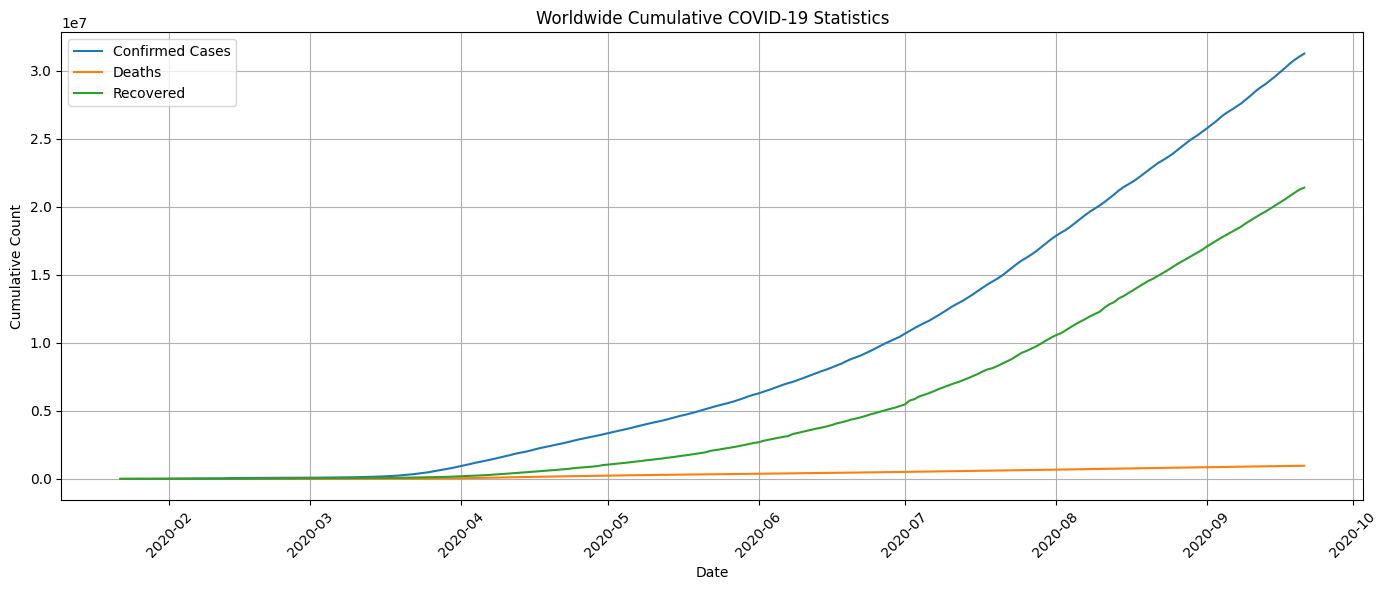

In [31]:
plt.figure(figsize=(14, 6))

plt.plot(
    eda_df["Date"],
    eda_df["Confirmed_Total"],
    label="Confirmed Cases"
)
plt.plot(
    eda_df["Date"],
    eda_df["Deaths_Total"],
    label="Deaths"
)
plt.plot(
    eda_df["Date"],
    eda_df["Recovered_Total"],
    label="Recovered"
)

plt.title("Worldwide Cumulative COVID-19 Statistics")
plt.xlabel("Date")
plt.ylabel("Cumulative Count")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

DAILY NEW CONFIRMED CASES

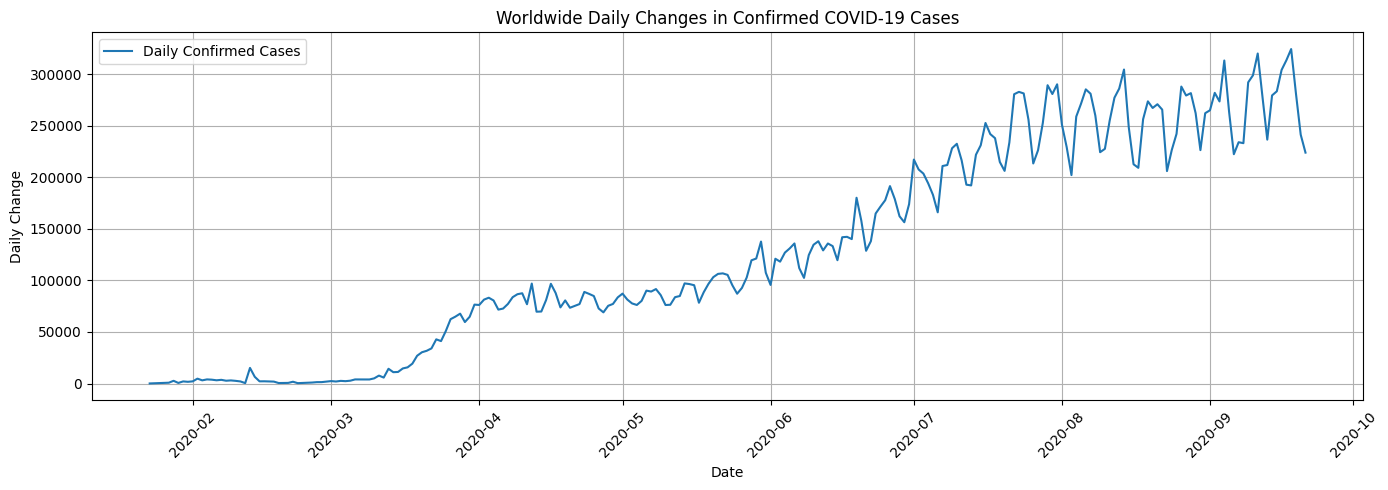

In [32]:
plt.figure(figsize=(14, 5))

plt.plot(
    eda_df["Date"],
    eda_df["Daily_Confirmed"],
    label="Daily Confirmed Cases"
)

plt.title("Worldwide Daily Changes in Confirmed COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("Daily Change")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

FIND THE COUNTRIES WITH MOST CONFIRMED CASES

,Confirmed Cases
Country/Region,
US,6856884
India,5487580
Brazil,4558040
Russia,1105048
Colombia,770435
Peru,768895
Mexico,700580
Spain,671468
South Africa,661936


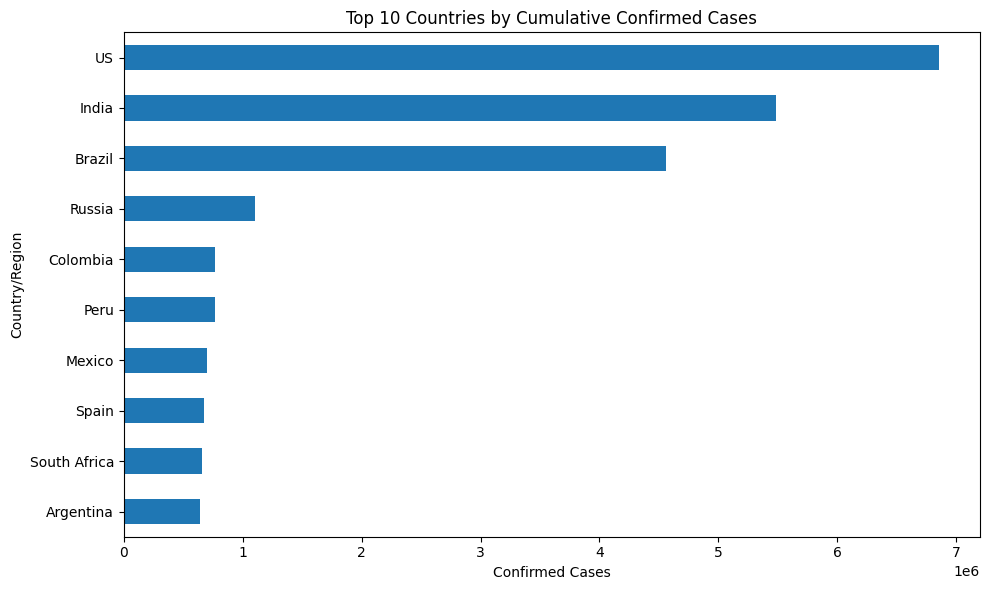

In [33]:
latest_date_col = next(
    col for col, _ in sorted(
        [
            (col, pd.to_datetime(str(col), errors="coerce"))
            for col in confirmed_df.columns
            if pd.notna(pd.to_datetime(str(col), errors="coerce"))
        ],
        key=lambda x: x[1],
        reverse=True
    )
)

country_column = next(
    (
        col for col in ["Country/Region", "Country_Region", "Country"]
        if col in confirmed_df.columns
    ),
    None
)

if country_column:
    country_totals = (
        confirmed_df.groupby(country_column)[latest_date_col]
        .sum()
        .sort_values(ascending=False)
        .head(10)
    )

    display(country_totals.rename("Confirmed Cases").to_frame())

    country_totals.sort_values().plot(
        kind="barh", figsize=(10, 6)
    )
    plt.title("Top 10 Countries by Cumulative Confirmed Cases")
    plt.xlabel("Confirmed Cases")
    plt.tight_layout()
    plt.show()
else:
    print("Country column not found. Available columns:")
    print(confirmed_df.columns.tolist())

CORRELATION ANALYSIS

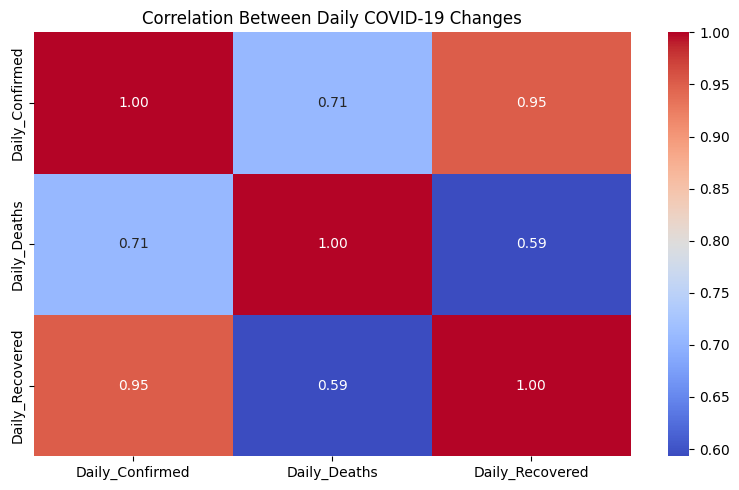

Correlation matrix:


,Daily_Confirmed,Daily_Deaths,Daily_Recovered
Daily_Confirmed,1.000000,0.707074,0.952029
Daily_Deaths,0.707074,1.000000,0.593168
Daily_Recovered,0.952029,0.593168,1.000000


In [34]:
daily_columns = [
    "Daily_Confirmed",
    "Daily_Deaths",
    "Daily_Recovered"
]

correlation = eda_df[daily_columns].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Daily COVID-19 Changes")
plt.tight_layout()
plt.show()

print("Correlation matrix:")
display(correlation)

EDA-SUMMARY

In [35]:
print("COVID-19 DATASET EDA SUMMARY")
print("-" * 40)

print("Start date:", eda_df["Date"].min().date())
print("End date:", eda_df["Date"].max().date())

print(
    "Latest cumulative confirmed cases:",
    int(eda_df["Confirmed_Total"].iloc[-1])
)
print(
    "Latest cumulative deaths:",
    int(eda_df["Deaths_Total"].iloc[-1])
)
print(
    "Latest cumulative recoveries:",
    int(eda_df["Recovered_Total"].iloc[-1])
)

print(
    "Negative daily confirmed changes:",
    int((eda_df["Daily_Confirmed"] < 0).sum())
)

print("EDA completed successfully.")

COVID-19 DATASET EDA SUMMARY
----------------------------------------
Start date: 2020-01-22
End date: 2020-09-21
Latest cumulative confirmed cases: 31245797
Latest cumulative deaths: 963693
Latest cumulative recoveries: 21394593
Negative daily confirmed changes: 0
EDA completed successfully.


DATA PREPROCESSING:

For the prediction, we will use the historical confirmed-case totals to calculate daily new confirmed cases.

In [36]:
ml_df = eda_df[["Date", "Confirmed_Total"]].copy()

ml_df["Daily_Confirmed"] = (
    ml_df["Confirmed_Total"].diff()
)

# The first row has no previous day, so remove it.
ml_df = ml_df.dropna().reset_index(drop=True)

print("Preprocessed dataset:")
display(ml_df.head())

print("Shape:", ml_df.shape)
print("Missing values:")
print(ml_df.isnull().sum())

Preprocessed dataset:


,Date,Confirmed_Total,Daily_Confirmed
0,2020-01-23,654,99.0
1,2020-01-24,941,287.0
2,2020-01-25,1434,493.0
3,2020-01-26,2118,684.0
4,2020-01-27,2927,809.0


Shape: (243, 3)
Missing values:
Date               0
Confirmed_Total    0
Daily_Confirmed    0
dtype: int64


Negative daily changes can reflect corrections to historical reports. We retain them here instead of automatically changing them to zero.

FEATURE ENGINEERING:

The model will learn from previous days' case counts to predict the next day's count.

In [37]:
ml_df["Lag_1"] = ml_df["Daily_Confirmed"].shift(1)
ml_df["Lag_2"] = ml_df["Daily_Confirmed"].shift(2)
ml_df["Lag_3"] = ml_df["Daily_Confirmed"].shift(3)
ml_df["Lag_7"] = ml_df["Daily_Confirmed"].shift(7)
ml_df["Lag_14"] = ml_df["Daily_Confirmed"].shift(14)

# Previous 7-day and 14-day averages
ml_df["Rolling_Mean_7"] = (
    ml_df["Daily_Confirmed"].shift(1).rolling(7).mean()
)
ml_df["Rolling_Mean_14"] = (
    ml_df["Daily_Confirmed"].shift(1).rolling(14).mean()
)

# Calendar features
ml_df["Day_of_Week"] = ml_df["Date"].dt.dayofweek
ml_df["Day_of_Year"] = ml_df["Date"].dt.dayofyear

ml_df = ml_df.dropna().reset_index(drop=True)

print("Features created successfully!")
display(ml_df.head())

Features created successfully!


,Date,Confirmed_Total,Daily_Confirmed,Lag_1,Lag_2,Lag_3,Lag_7,Lag_14,Rolling_Mean_7,Rolling_Mean_14,Day_of_Week,Day_of_Year
0,2020-02-06,30802,3159.0,3745.0,4011.0,3100.0,2068.0,99.0,3068.142857,1934.857143,3,37
1,2020-02-07,34395,3593.0,3159.0,3745.0,4011.0,1692.0,287.0,3224.000000,2153.428571,4,38
2,2020-02-08,37129,2734.0,3593.0,3159.0,3745.0,2112.0,493.0,3495.571429,2389.571429,5,39
3,2020-02-09,40159,3030.0,2734.0,3593.0,3159.0,4749.0,684.0,3584.428571,2549.642857,6,40
4,2020-02-10,42768,2609.0,3030.0,2734.0,3593.0,3100.0,809.0,3338.857143,2717.214286,0,41


SPLIT TRAINING AND TESTING DATA:

We use the earlier 80% of dates for training and the later 20% for testing. This preserves the time order.

In [38]:
feature_columns = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_7",
    "Lag_14",
    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Day_of_Week",
    "Day_of_Year"
]

X = ml_df[feature_columns]
y = ml_df["Daily_Confirmed"]

split_index = int(len(ml_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

test_dates = ml_df["Date"].iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training dates:", ml_df["Date"].iloc[0], "to",
      ml_df["Date"].iloc[split_index - 1])
print("Testing dates:", test_dates.iloc[0], "to",
      test_dates.iloc[-1])

Training samples: 183
Testing samples: 46
Training dates: 2020-02-06 00:00:00 to 2020-08-06 00:00:00
Testing dates: 2020-08-07 00:00:00 to 2020-09-21 00:00:00


LINEAR REGRESSION

In [39]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

LinearRegression()

In [40]:
linear_predictions = linear_model.predict(X_test)

print("Linear Regression training completed!")
print("First 10 predictions:")
print(linear_predictions[:10])

Linear Regression training completed!
First 10 predictions:
[277750.05716893 247835.37494636 221370.39642074 209106.444297
 254508.17185931 282346.29929509 289448.89530877 285196.06500096
 268434.14859005 231103.51583614]


RANDOM FOREST REGRESSOR

In [41]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10,
    min_samples_leaf=2,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, min_samples_leaf=2, n_estimators=200,
                      n_jobs=-1, random_state=42)

In [42]:
rf_predictions = rf_model.predict(X_test)

print("Random Forest training completed!")
print("First 10 predictions:")
print(rf_predictions[:10])

Random Forest training completed!
First 10 predictions:
[272807.08720238 264582.31831349 255222.21176587 229784.71785714
 262537.52168254 275301.68208135 276782.69415278 270432.3177381
 263719.15628571 230997.626     ]


XGBOOST REGRESSOR

In [43]:
%pip -q install xgboost

In [44]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [45]:
xgb_predictions = xgb_model.predict(X_test)

print("XGBoost training completed!")
print("First 10 predictions:")
print(xgb_predictions[:10])

XGBoost training completed!
First 10 predictions:
[269513.16 263360.03 245708.03 225144.36 253676.2  270452.   276274.38
 263657.22 253619.56 224381.36]


EVALUATED AND COMPARED ALL THE THREE MODELS:

In [46]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = {
    "Linear Regression": linear_predictions,
    "Random Forest": rf_predictions,
    "XGBoost": xgb_predictions
}

results = []

for model_name, pred in predictions.items():
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print("MODEL COMPARISON RESULTS")
display(results_df.round(3))

best_model = results_df.loc[
    results_df["MAE"].idxmin(), "Model"
]

print("Best model based on MAE:", best_model)

MODEL COMPARISON RESULTS


,Model,MAE,RMSE,R2 Score
0,Linear Regression,14297.844,17681.659,0.663
1,Random Forest,16854.139,22053.669,0.476
2,XGBoost,18064.138,24683.156,0.343


Best model based on MAE: Linear Regression


VISUALIZE ACTUAL VERSUS PREDICTED CASES:

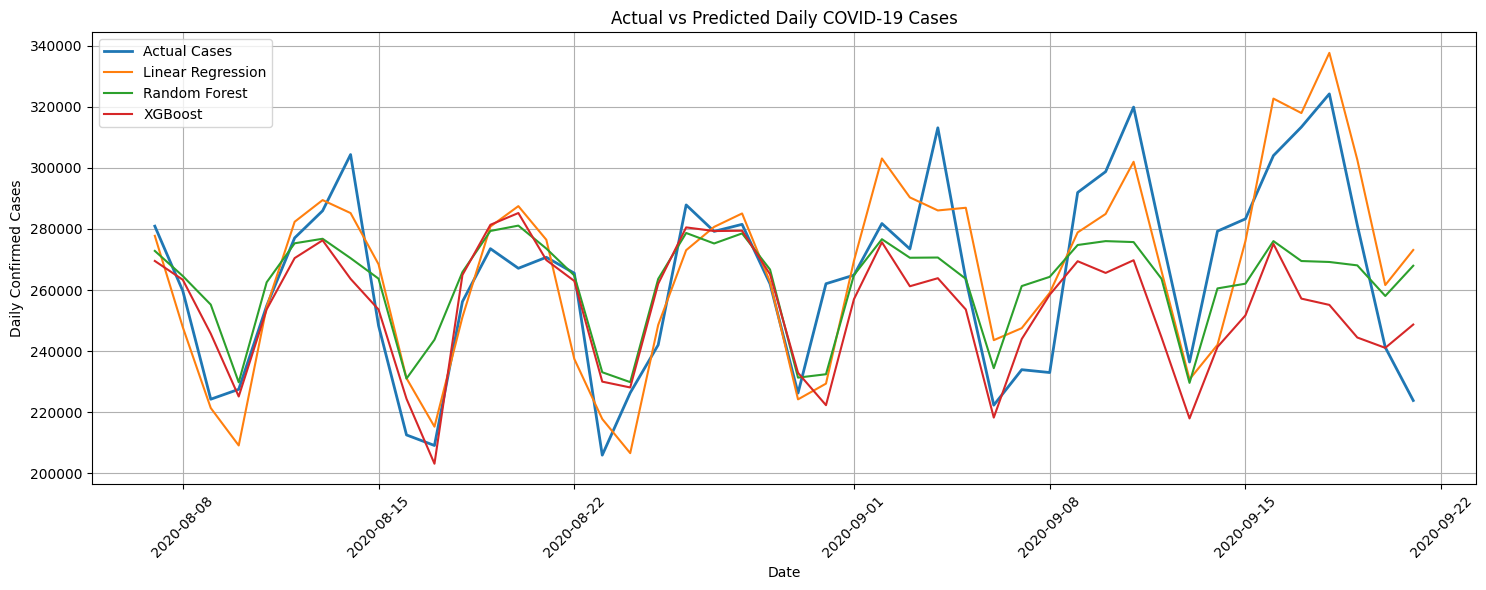

In [47]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_dates,
    y_test.to_numpy(),
    label="Actual Cases",
    linewidth=2
)

plt.plot(
    test_dates,
    linear_predictions,
    label="Linear Regression"
)

plt.plot(
    test_dates,
    rf_predictions,
    label="Random Forest"
)

plt.plot(
    test_dates,
    xgb_predictions,
    label="XGBoost"
)

plt.title("Actual vs Predicted Daily COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("Daily Confirmed Cases")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

COMPARED MODEL PERFORMANCES WITH GRAPH:

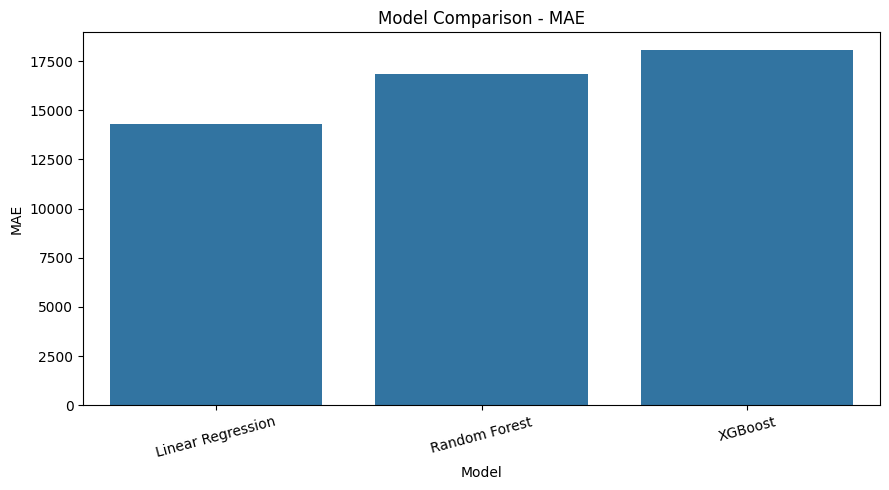

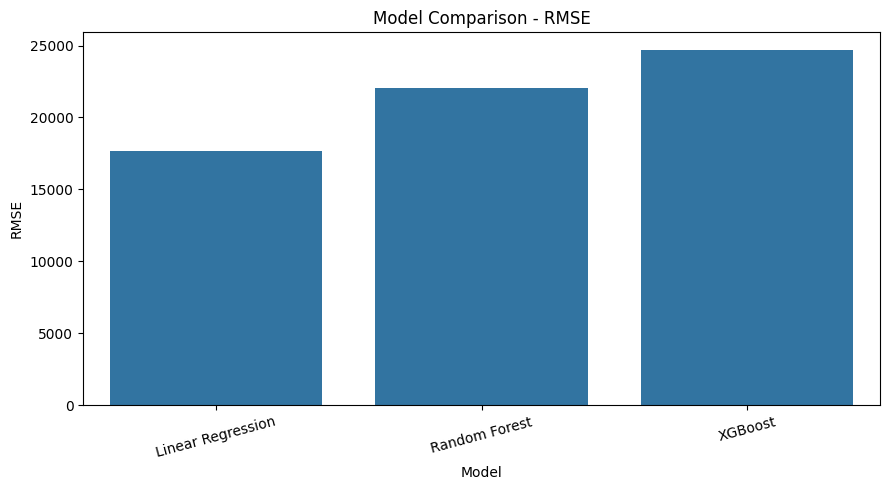

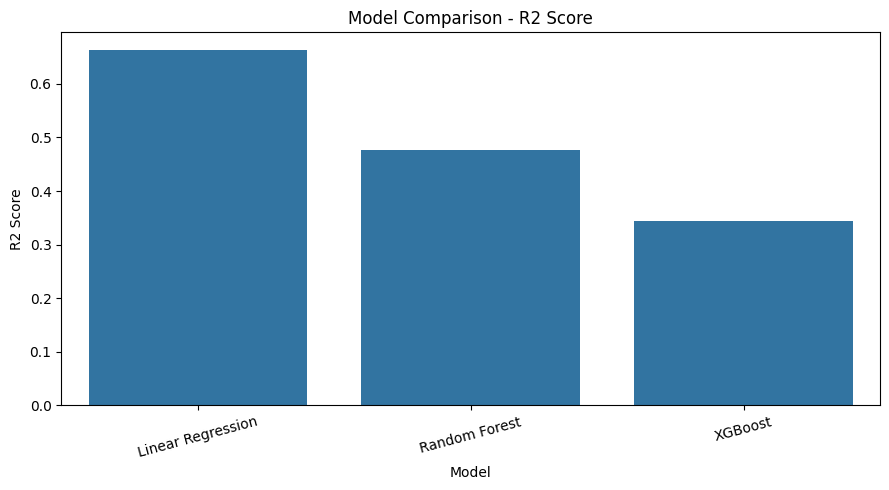

In [48]:
# Compare MAE
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Model Comparison - MAE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Compare RMSE
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="RMSE")
plt.title("Model Comparison - RMSE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Compare R2
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score")
plt.title("Model Comparison - R2 Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

SAVE THE PREDICTION RESULTS:

In [49]:
prediction_results = pd.DataFrame({
    "Date": test_dates.to_numpy(),
    "Actual_Cases": y_test.to_numpy(),
    "Linear_Regression": linear_predictions,
    "Random_Forest": rf_predictions,
    "XGBoost": xgb_predictions
})

prediction_results.to_csv(
    "covid19_prediction_results.csv",
    index=False
)

results_df.to_csv(
    "covid19_model_comparison.csv",
    index=False
)

print("Prediction results saved successfully!")

display(prediction_results.head(10))

Prediction results saved successfully!


,Date,Actual_Cases,Linear_Regression,Random_Forest,XGBoost
0,2020-08-07,280911.0,277750.057169,272807.087202,269513.156250
1,2020-08-08,259730.0,247835.374946,264582.318313,263360.031250
2,2020-08-09,224250.0,221370.396421,255222.211766,245708.031250
3,2020-08-10,227488.0,209106.444297,229784.717857,225144.359375
4,2020-08-11,254827.0,254508.171859,262537.521683,253676.203125
5,2020-08-12,277067.0,282346.299295,275301.682081,270452.000000
6,2020-08-13,285949.0,289448.895309,276782.694153,276274.375000
7,2020-08-14,304351.0,285196.065001,270432.317738,263657.218750
8,2020-08-15,248352.0,268434.148590,263719.156286,253619.562500
9,2020-08-16,212550.0,231103.515836,230997.626000,224381.359375


GENERATE THE CONCLUSION FROM THE RESULTS:

This prints a conclusion using the actual scores produced by your models, rather than assuming which model performed best.

In [50]:
best_row = results_df.loc[results_df["MAE"].idxmin()]

print("PROJECT CONCLUSION")
print("=" * 60)

print(
    "This project predicts daily worldwide COVID-19 confirmed "
    "cases using historical time-series data."
)

print(
    "Three machine learning algorithms were evaluated: "
    "Linear Regression, Random Forest Regressor, and XGBoost Regressor."
)

print(
    f"Based on the lowest MAE, {best_row['Model']} "
    "performed best among the three models on the test data."
)

print(f"MAE: {best_row['MAE']:.3f}")
print(f"RMSE: {best_row['RMSE']:.3f}")
print(f"R2 Score: {best_row['R2 Score']:.3f}")

print(
    "The comparison demonstrates how different regression algorithms "
    "perform when forecasting daily case counts from previous observations."
)

print(
    "These results apply to the historical dataset and do not establish "
    "reliable predictions of current COVID-19 conditions."
)

PROJECT CONCLUSION
This project predicts daily worldwide COVID-19 confirmed cases using historical time-series data.
Three machine learning algorithms were evaluated: Linear Regression, Random Forest Regressor, and XGBoost Regressor.
Based on the lowest MAE, Linear Regression performed best among the three models on the test data.
MAE: 14297.844
RMSE: 17681.659
R2 Score: 0.663
The comparison demonstrates how different regression algorithms perform when forecasting daily case counts from previous observations.
These results apply to the historical dataset and do not establish reliable predictions of current COVID-19 conditions.


CONCLUSION:


The COVID-19 Cases Prediction project successfully implemented and compared three machine learning algorithms: Linear Regression, Random Forest Regressor, and XGBoost Regressor.

Based on the experimental results, Linear Regression performed the best, achieving the lowest Mean Absolute Error (MAE) of 14,297.844, the lowest Root Mean Squared Error (RMSE) of 17,681.650, and the highest R² score of 0.663.

Random Forest achieved an R² score of 0.476, while XGBoost achieved an R² score of 0.343. Therefore, Linear Regression was selected as the best model among the three algorithms for predicting daily new COVID-19 cases using the test dataset.

The results demonstrate that Linear Regression performed better than the other tested models on this dataset. However, the predictions are based on historical data and should not be considered reliable forecasts of current COVID-19 conditions.

Best model: Linear Regression

The R² score of 0.663 means the model explains approximately 66.3% of the variation in the test-set target values.